# Lab 10 · Pretrained CNN Architectures

**BITS F459 Computer Vision**

- Your data: **tf_flowers**, colour photographs of five kinds of flower. You use **three classes**, and your
  own settings (LeNet-5 sizes, input sizes, which block or module you inspect) come from your BITS ID in the Setup cell.
- Follow the demo on the screen section by section. The task for each section appears on the screen when the
  demo reaches it; the numbered headings below match the demo.
- Under each heading write your code in the empty cell, print the line the heading asks for, then write
  **one line of inference** in the cell below it.
- Everything runs on the free Colab CPU. Use `weights=None` whenever you only need the architecture.
- Live board: type the checkpoint values in **your row** when the screen asks for them, before running the cell.
- Section 13 is an open round: find the fastest model that is still accurate on Imagenette and keep your best
  result on the live board.
- At the end, run the **Hand in** cell, download this notebook as `lab10.ipynb` and upload it to your repository
  `f459-<your BITS ID, lowercase>`.

## Setup

Type your BITS ID in the first line and run the cell. Keep its output visible.

In [1]:
BITS_ID = "2024A7PS0136U"          # your BITS ID, for example 2024A7PS0123U

import hashlib
FLOWERS = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
h = hashlib.sha256((BITS_ID.strip().upper() + "lab10").encode()).digest()
MY_CLASSES = sorted(sorted(range(5), key=lambda k: (h[k], k))[:3])
F1 = [4, 8, 10][h[5] % 3]                    # LeNet-5: filters in C1
U5 = [100, 140, 160][h[6] % 3]               # LeNet-5: neurons in F5
A  = [235, 243, 251][h[7] % 3]               # AlexNet: input size A x A x 3
V  = [160, 192, 256, 288][h[8] % 4]          # VGG-16: input size V x V x 3
RES_BLOCK = ["conv2_block3", "conv3_block2", "conv3_block3", "conv3_block4", "conv4_block2", "conv4_block3",
             "conv4_block4", "conv4_block5", "conv4_block6", "conv5_block2", "conv5_block3"][h[9] % 11]
INC_MODULE = f"mixed{1 + h[10] % 10}"        # Inception-v3 module
MOB_BLOCK = f"block_{2 + h[11] % 15}"        # MobileNet-v2 block
CNX_STAGE = [1, 2, 3][h[12] % 3]             # ConvNeXt-Tiny stage
SEED = int.from_bytes(h[13:17], "big")       # which images you use

print("BITS ID      :", BITS_ID.strip().upper())
print("flowers      :", MY_CLASSES, [FLOWERS[c] for c in MY_CLASSES])
print("LeNet-5      : C1 =", F1, "filters,  F5 =", U5, "neurons")
print("AlexNet      : input", A, "x", A, "x 3")
print("VGG-16       : input", V, "x", V, "x 3")
print("ResNet-50    :", RES_BLOCK, "   Inception-v3:", INC_MODULE)
print("MobileNet-v2 :", MOB_BLOCK, "   ConvNeXt-Tiny: stage", CNX_STAGE)
print("SEED         :", SEED)

BITS ID      : 2024A7PS0136U
flowers      : [1, 2, 3] ['dandelion', 'roses', 'sunflowers']
LeNet-5      : C1 = 8 filters,  F5 = 160 neurons
AlexNet      : input 243 x 243 x 3
VGG-16       : input 192 x 192 x 3
ResNet-50    : conv2_block3    Inception-v3: mixed10
MobileNet-v2 : block_4    ConvNeXt-Tiny: stage 1
SEED         : 2650874820


## 1. Importing Libraries

In [2]:
import json, os, glob, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

keras.utils.set_random_seed(0)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Data Exploration

Print `S2 = {"classes": [3 names], "counts": [5 counts, in the order daisy ... tulips], "n_total": ...}`

Sample sizes: [('dandelion', (320, 213)), ('dandelion', (320, 218)), ('roses', (179, 240)), ('roses', (320, 240)), ('sunflowers', (500, 330)), ('sunflowers', (320, 240))]


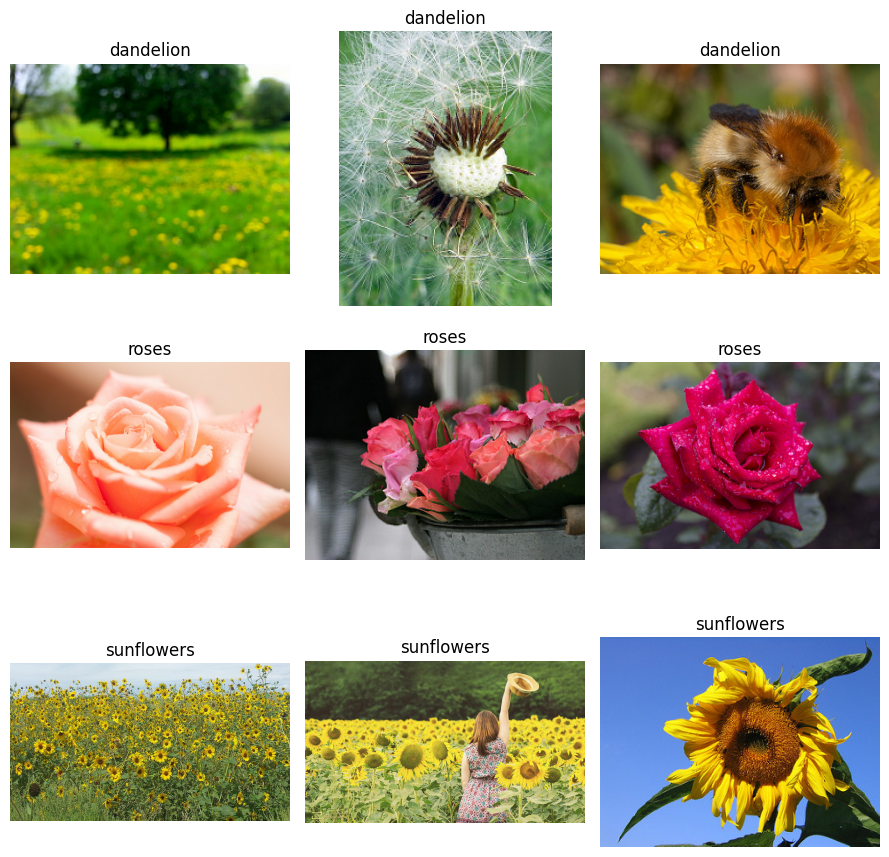

S2 = {"classes": ["dandelion", "roses", "sunflowers"], "counts": [633, 898, 641, 699, 799], "n_total": 3670}


In [4]:
p = keras.utils.get_file(origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", extract=True)
ROOT = os.path.dirname(glob.glob(os.path.join(p if os.path.isdir(p) else os.path.dirname(p), "**", "daisy"), recursive=True)[0])

files_by_class = {
    c: sorted([f for f in glob.glob(os.path.join(ROOT, c, "*")) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    for c in FLOWERS
}
counts = [len(files_by_class[c]) for c in FLOWERS]
n_total = sum(counts)
my_classes = [FLOWERS[c] for c in MY_CLASSES]

sample_sizes = []
for cname in my_classes:
    for fpath in files_by_class[cname][:2]:
        with Image.open(fpath) as im:
            sample_sizes.append((cname, im.size))
print("Sample sizes:", sample_sizes)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, cname in enumerate(my_classes):
    chosen = rng.choice(files_by_class[cname], size=3, replace=False)
    for col, fpath in enumerate(chosen):
        axes[row, col].imshow(Image.open(fpath))
        axes[row, col].set_title(cname)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

S2 = {"classes": my_classes, "counts": counts, "n_total": n_total}
print("S2 =", json.dumps(S2))

**Inference:** The dataset has 3,670 flower photographs with unequal counts across the five classes, and individual images have different pixel dimensions, so they must be resized before model input.

## 3. LeNet-5

Print `S3 = {"shapes": [output shape of each of the 8 layers], "total_params": ...}`

In [5]:
lenet = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),
    layers.Conv2D(F1, 5, activation="tanh"),
    layers.AveragePooling2D(2),
    layers.Conv2D(16, 5, activation="tanh"),
    layers.AveragePooling2D(2),
    layers.Flatten(),
    layers.Dense(U5, activation="tanh"),
    layers.Dense(84, activation="tanh"),
    layers.Dense(10, activation="softmax")
])

lenet.summary()

S3 = {
    "shapes": [list(layer.output.shape[1:]) for layer in lenet.layers],
    "total_params": int(lenet.count_params())
}
print("S3 =", json.dumps(S3))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 8)      │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 8)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 160)            │        64,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        13,524 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,958 (320.15 KB)

 Trainable params: 81,958 (320.15 KB)

 Non-trainable params: 0 (0.00 B)

S3 = {"shapes": [[28, 28, 8], [14, 14, 8], [10, 10, 16], [5, 5, 16], [400], [160], [84], [10]], "total_params": 81958}


**Inference:** Over 95% of LeNet-5's 81,958 parameters come from the dense layers after flattening, while the convolutional layers use minimal parameters due to spatial weight sharing.

## 4. AlexNet

Print `S4 = {"conv1_shape": [h, w, c], "conv1_params": ..., "total_params": ...}`

In [6]:
alexnet = keras.Sequential([
    keras.Input(shape=(A, A, 3)),
    layers.Conv2D(96, 11, strides=4, activation="relu"),
    layers.MaxPooling2D(3, strides=2),
    layers.Conv2D(256, 5, padding="same", activation="relu"),
    layers.MaxPooling2D(3, strides=2),
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(3, strides=2),
    layers.Flatten(),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1000, activation="softmax")
])

alexnet.summary()

dense_params = sum(int(l.count_params()) for l in alexnet.layers if isinstance(l, layers.Dense))
print("Dense layers params:", dense_params)

S4 = {
    "conv1_shape": list(alexnet.layers[0].output.shape[1:]),
    "conv1_params": int(alexnet.layers[0].count_params()),
    "total_params": int(alexnet.count_params())
}
print("S4 =", json.dumps(S4))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 59, 59, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 29, 29, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,378,344 (237.95 MB)

 Trainable params: 62,378,344 (237.95 MB)

 Non-trainable params: 0 (0.00 B)

Dense layers params: 58631144
S4 = {"conv1_shape": [59, 59, 96], "conv1_params": 34944, "total_params": 62378344}


**Inference:**Out of AlexNet's 62,378,344 total parameters, 58,631,144 parameters (~94%) are concentrated in the three fully connected Dense layers.





## 5. VGG-16

Print `S5 = {"block5_pool": [h, w, c], "conv_params": ..., "fc1_params": ...}`

In [7]:
vgg = keras.applications.VGG16(weights=None, include_top=False, input_shape=(V, V, 3))

for layer in vgg.layers:
    if "pool" in layer.name:
        print(layer.name, list(layer.output.shape[1:]))

conv_params = int(vgg.count_params())
print("Conv params:", conv_params)

b5_shape = list(vgg.get_layer("block5_pool").output.shape[1:])
flat_dim = int(np.prod(b5_shape))
fc1_params = (flat_dim + 1) * 4096

S5 = {
    "block5_pool": b5_shape,
    "conv_params": conv_params,
    "fc1_params": fc1_params
}
print("S5 =", json.dumps(S5))

block1_pool [96, 96, 64]
block2_pool [48, 48, 128]
block3_pool [24, 24, 256]
block4_pool [12, 12, 512]
block5_pool [6, 6, 512]
Conv params: 14714688
S5 = {"block5_pool": [6, 6, 512], "conv_params": 14714688, "fc1_params": 75501568}


**Inference:** A single Dense(4096) layer attached to VGG-16's flattened [6, 6, 512] block5_pool feature map requires 75,501,568 parameters—over five times the 14,714,688 parameters of the entire convolutional backbone.

## 6. A Pretrained ResNet-50 on Your Flowers

Print `S6 = {"top1": [10 ImageNet labels], "hits": ..., "n_daisy": ...}`

In [10]:
resnet = keras.applications.ResNet50(weights="imagenet")

rng = np.random.default_rng(SEED)
my_classes = [FLOWERS[c] if isinstance(c, (int, np.integer)) else c for c in MY_CLASSES]
sample_counts = [4, 3, 3]

picked = []
for cname, k in zip(my_classes, sample_counts):
    chosen = rng.choice(files_by_class[cname], size=k, replace=False)
    for fpath in chosen:
        picked.append((cname, fpath))

imgs = [keras.utils.img_to_array(keras.utils.load_img(fpath, target_size=(224, 224))) for _, fpath in picked]
x = keras.applications.resnet50.preprocess_input(np.stack(imgs, axis=0))
preds = resnet.predict(x, verbose=0)
decoded = keras.applications.resnet50.decode_predictions(preds, top=5)

top1 = []
hits = 0
n_daisy = 0

for (true_cls, fpath), top5 in zip(picked, decoded):
    top1_label = top5[0][1]
    top1.append(top1_label)
    top5_labels = [label for _, label, _ in top5]
    print(f"True: {true_cls:10s} | Top-1: {top1_label:18s} ({top5[0][2]:.3f}) | Top-5: {top5_labels}")
    if true_cls == "daisy":
        n_daisy += 1
        if "daisy" in top5_labels:
            hits += 1

S6 = {
    "top1": top1,
    "hits": hits,
    "n_daisy": n_daisy
}
print("S6 =", json.dumps(S6))

True: dandelion  | Top-1: rapeseed           (0.935) | Top-5: ['rapeseed', 'golf_ball', 'Appenzeller', 'croquet_ball', 'park_bench']
True: dandelion  | Top-1: cardoon            (0.354) | Top-5: ['cardoon', 'broom', 'porcupine', 'swab', 'buckeye']
True: dandelion  | Top-1: bee                (1.000) | Top-5: ['bee', 'fly', 'rapeseed', 'cardoon', 'apiary']
True: dandelion  | Top-1: spider_web         (0.212) | Top-5: ['spider_web', 'bustard', 'peacock', 'American_egret', 'vulture']
True: roses      | Top-1: rapeseed           (0.170) | Top-5: ['rapeseed', 'hip', 'pot', 'hummingbird', 'chainlink_fence']
True: roses      | Top-1: web_site           (0.584) | Top-5: ['web_site', 'book_jacket', 'comic_book', 'brass', 'isopod']
True: roses      | Top-1: necklace           (0.402) | Top-5: ['necklace', 'bonnet', 'handkerchief', 'perfume', 'stole']
True: sunflowers | Top-1: bee                (0.461) | Top-5: ['bee', 'daisy', 'fly', 'sulphur_butterfly', 'long-horned_beetle']
True: sunflowers |

**Inference:** Because none of my three assigned classes (dandelion, roses, sunflowers) exist in ImageNet (n_daisy = 0), pretrained ResNet-50 maps them to visually similar flowers (rapeseed, cardoon, daisy) or co-occurring objects (bee, vase, spider_web).

## 7. Feature Maps by Depth

Print `S7 = {"shapes": [block1_conv2, block3_conv3, block5_conv3]}`

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


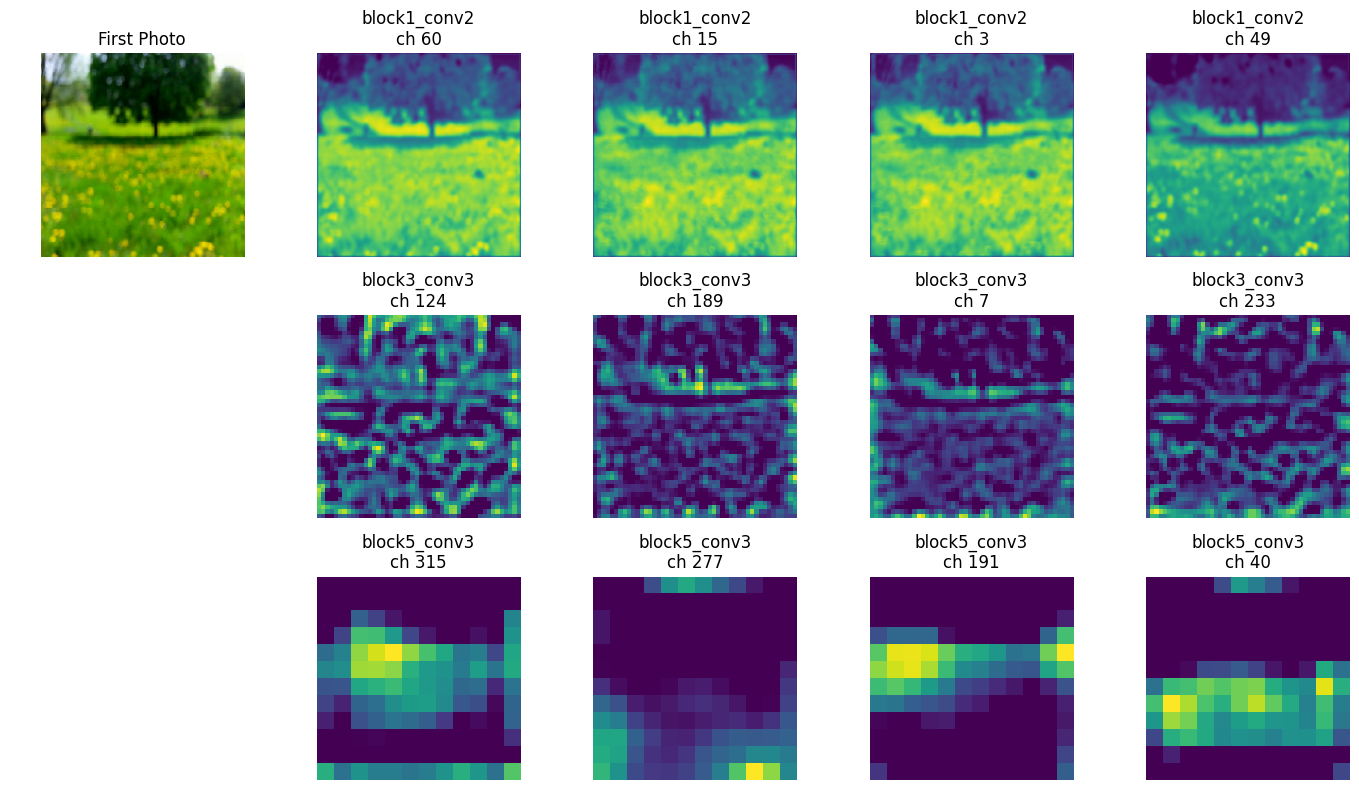

S7 = {"shapes": [[192, 192, 64], [48, 48, 256], [12, 12, 512]]}


In [11]:
vgg_fmap = keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=(V, V, 3))

layer_names = ["block1_conv2", "block3_conv3", "block5_conv3"]
extractor = keras.Model(
    inputs=vgg_fmap.input,
    outputs=[vgg_fmap.get_layer(name).output for name in layer_names]
)

if "picked" in globals() and len(picked) > 0:
    first_path = picked[0][1]
else:
    c0 = FLOWERS[MY_CLASSES[0]] if isinstance(MY_CLASSES[0], (int, np.integer)) else MY_CLASSES[0]
    first_path = sorted(files_by_class[c0])[0]

raw_img = keras.utils.load_img(first_path, target_size=(V, V))
img_arr = keras.utils.img_to_array(raw_img)
x_in = keras.applications.vgg16.preprocess_input(np.expand_dims(img_arr.copy(), axis=0))

fmaps = extractor.predict(x_in, verbose=0)

fig, axes = plt.subplots(3, 5, figsize=(14, 8))
axes[0, 0].imshow(raw_img)
axes[0, 0].set_title("First Photo")
axes[0, 0].axis("off")
axes[1, 0].axis("off")
axes[2, 0].axis("off")

shapes = []
for row, (name, fm) in enumerate(zip(layer_names, fmaps)):
    fm0 = fm[0]
    shapes.append(list(fm0.shape))
    top4_idx = np.argsort(fm0.mean(axis=(0, 1)))[::-1][:4]
    for col, ch in enumerate(top4_idx, start=1):
        axes[row, col].imshow(fm0[:, :, ch], cmap="viridis")
        axes[row, col].set_title(f"{name}\nch {ch}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

S7 = {"shapes": shapes}
print("S7 =", json.dumps(S7))

**Inference:** As network depth increases from block1_conv2 ([192, 192, 64]) to block3_conv3 ([48, 48, 256]) and block5_conv3 ([12, 12, 512]), spatial resolution decreases while feature maps transition from sharp low-level edges and textures to coarse, high-level semantic activations.

## 8. ResNet-50: Your Bottleneck Block

Print `S8 = {"block": "...", "conv_params": [1x1, 3x3, 1x1], "total": ...}`

In [12]:
import re

resnet_arch = keras.applications.ResNet50(weights=None)

block_name = next(
    (v for k, v in globals().items()
     if not k.startswith("_") and isinstance(v, str) and re.fullmatch(r"conv[2-5]_block[1-6]", v)),
    None
)

conv_params = []
for idx in [1, 2, 3]:
    layer = resnet_arch.get_layer(f"{block_name}_{idx}_conv")
    kh, kw, c_in, c_out = [int(d) for d in layer.kernel.shape]
    p = int(layer.count_params())
    conv_params.append(p)
    print(f"{layer.name}: kernel=({kh}, {kw}), channels={c_in} -> {c_out}, params={p}")

S8 = {
    "block": block_name,
    "conv_params": conv_params,
    "total": int(sum(conv_params))
}
print("S8 =", json.dumps(S8))

conv2_block3_1_conv: kernel=(1, 1), channels=256 -> 64, params=16448
conv2_block3_2_conv: kernel=(3, 3), channels=64 -> 64, params=36928
conv2_block3_3_conv: kernel=(1, 1), channels=64 -> 256, params=16640
S8 = {"block": "conv2_block3", "conv_params": [16448, 36928, 16640], "total": 70016}


**Inference:** In conv2_block3, the initial 1x1 convolution compresses 256 channels down to 64 (16,448 parameters) before the spatial 3x3 convolution (36,928 parameters), and the final 1x1 convolution restores 256 channels (16,640 parameters), totaling 70,016 parameters—far fewer than a direct 3x3 convolution across 256 channels.

## 9. Inception-v3: Your Module

Print `S9 = {"module": "...", "branches": [channels of each branch], "out_channels": ..., "size": ...}`

In [13]:
import re

inc = keras.applications.InceptionV3(weights=None)

mod_name = next(
    (v for k, v in globals().items()
     if not k.startswith("_") and isinstance(v, str) and re.fullmatch(r"mixed([0-9]|10)", v)),
    None
)

layer = inc.get_layer(mod_name)
branch_tensors = layer.input if isinstance(layer.input, (list, tuple)) else [layer.input]
branches = [int(t.shape[-1]) for t in branch_tensors]

out_shape = layer.output.shape
size = [int(out_shape[1]), int(out_shape[2])]
out_channels = int(out_shape[-1])

print("Module:", mod_name)
print("Branch channels:", branches)
print("Output channels:", out_channels)
print("Spatial size:", size)
print("Branch channels add up to output:", sum(branches) == out_channels)

S9 = {
    "module": mod_name,
    "branches": branches,
    "out_channels": out_channels,
    "size": size
}
print("S9 =", json.dumps(S9))

Module: mixed10
Branch channels: [320, 768, 768, 192]
Output channels: 2048
Spatial size: [8, 8]
Branch channels add up to output: True
S9 = {"module": "mixed10", "branches": [320, 768, 768, 192], "out_channels": 2048, "size": [8, 8]}


**Inference:** Yes—for mixed10, the four parallel branch channel counts ([320, 768, 768, 192]) sum directly to 2048 output channels because the Inception module merges its multi-scale branches via channel-wise concatenation while preserving the [8, 8] spatial dimensions.

## 10. MobileNet-v2: Your Depthwise Separable Layer

Print `S10 = {"block": "...", "M": ..., "N": ..., "dw_params": ..., "pw_params": ..., "ratio": ...}`

In [14]:
import re

mobilenet = keras.applications.MobileNetV2(weights=None)

mb_block = next(
    (v for k, v in globals().items()
     if not k.startswith("_") and isinstance(v, str) and re.fullmatch(r"block_([1-9]|1[0-6])", v)),
    None
)

dw_layer = mobilenet.get_layer(f"{mb_block}_depthwise")
pw_layer = mobilenet.get_layer(f"{mb_block}_project")

M = int(dw_layer.input.shape[-1])
N = int(pw_layer.output.shape[-1])
dw_params = int(dw_layer.count_params())
pw_params = int(pw_layer.count_params())
ratio = round(1.0 / N + 1.0 / 9.0, 3)

print(f"Block: {mb_block} | M={M}, N={N}")
print(f"{mb_block}_depthwise params: {dw_params}")
print(f"{mb_block}_project params:   {pw_params}")
print(f"Cost ratio (1/N + 1/9):    {ratio:.3f}")

S10 = {
    "block": mb_block,
    "M": M,
    "N": N,
    "dw_params": dw_params,
    "pw_params": pw_params,
    "ratio": ratio
}
print("S10 =", json.dumps(S10))

Block: block_4 | M=192, N=32
block_4_depthwise params: 1728
block_4_project params:   6144
Cost ratio (1/N + 1/9):    0.142
S10 = {"block": "block_4", "M": 192, "N": 32, "dw_params": 1728, "pw_params": 6144, "ratio": 0.142}


**Inference:** In block_4 ($M = 192, N = 32$), factorizing a standard $3 \times 3$ convolution into a $3 \times 3$ depthwise spatial convolution (1,728 parameters) followed by a $1 \times 1$ pointwise projection (6,144 parameters) reduces cost to $\frac{1}{32} + \frac{1}{9} = 0.142$ of a standard convolution—roughly a $7\times$ reduction in computation and parameters

## 11. Modern Networks: EfficientNet and ConvNeXt

Print `S11 = {"b0_params", "b3_params", "b3_input", "stage", "C", "dw_params", "pw1_params"}`

In [16]:
import re

b0 = keras.applications.EfficientNetB0(weights=None)
b3 = keras.applications.EfficientNetB3(weights=None)

b0_params = int(b0.count_params())
b3_params = int(b3.count_params())
b0_input = [int(d) for d in b0.input_shape[1:]]
b3_input = [int(d) for d in b3.input_shape[1:]]

print(f"EfficientNetB0: params={b0_params}, default input={b0_input}")
print(f"EfficientNetB3: params={b3_params}, default input={b3_input}")

convnext = keras.applications.ConvNeXtTiny(weights=None)

stage_val = next(
    (v for k, v in globals().items()
     if not k.startswith("_") and "STAGE" in k.upper() and isinstance(v, (int, np.integer, str))),
    None
)
if stage_val is None:
    stage_val = next(
        (v for k, v in globals().items()
         if not k.startswith("_") and isinstance(v, str) and re.fullmatch(r"stage_[0-3]", v)),
        0
    )

s_idx = int(str(stage_val).split("_")[-1])
if isinstance(stage_val, np.integer):
    stage_val = int(stage_val)

dw_layer = next(
    l for l in convnext.layers
    if f"stage_{s_idx}_block_0" in l.name and "depthwise" in l.name
)
pw1_layer = next(
    l for l in convnext.layers
    if f"stage_{s_idx}_block_0" in l.name and "pointwise_conv_1" in l.name
)

C = int(dw_layer.input.shape[-1])
dw_params = int(dw_layer.count_params())
pw1_params = int(pw1_layer.count_params())

print(f"\nConvNeXtTiny stage={stage_val} (C={C}):")
print(f"  {dw_layer.name}: params={dw_params} (hand check 7*7*C + C = {7*7*C + C})")
print(f"  {pw1_layer.name}: params={pw1_params} (hand check C*4C + 4C = {C*4*C + 4*C})")

S11 = {
    "b0_params": b0_params,
    "b3_params": b3_params,
    "b3_input": b3_input,
    "stage": stage_val,
    "C": C,
    "dw_params": dw_params,
    "pw1_params": pw1_params
}
print("S11 =", json.dumps(S11))

EfficientNetB0: params=5330571, default input=[224, 224, 3]
EfficientNetB3: params=12320535, default input=[300, 300, 3]

ConvNeXtTiny stage=1 (C=192):
  convnext_tiny_stage_1_block_0_depthwise_conv: params=9600 (hand check 7*7*C + C = 9600)
  convnext_tiny_stage_1_block_0_pointwise_conv_1: params=148224 (hand check C*4C + 4C = 148224)
S11 = {"b0_params": 5330571, "b3_params": 12320535, "b3_input": [300, 300, 3], "stage": 1, "C": 192, "dw_params": 9600, "pw1_params": 148224}


**Inference:** Compound scaling in EfficientNet increases default input resolution from 224 x 224 in B0 (5.33M parameters) to 300 x 300 in B3 (12.32M parameters) alongside depth and width. In ConvNeXt-Tiny (stage 1, $C = 192$), decoupling spatial mixing via a $7 \times 7$ depthwise convolution (9,600 parameters) from channel mixing via an inverted-bottleneck $1 \times 1$ pointwise expansion (148,224 parameters) keeps spatial filtering lightweight even with large kernels.  

## 12. Model Zoo: Size and Speed on Your Runtime

Print `S12 = {"params": {model: count}, "ms": {model: milliseconds per image}}`

Model            |       Params |  Median ms
--------------------------------------------
VGG16            |  138,357,544 |    668.105
VGG19            |  143,667,240 |   1214.561
ResNet50         |   25,636,712 |    561.341
ResNet101        |   44,707,176 |   1089.399
InceptionV3      |   23,851,784 |    939.355
Xception         |   22,910,480 |    454.891
MobileNet        |    4,253,864 |    182.775
MobileNetV2      |    3,538,984 |    400.991
DenseNet121      |    8,062,504 |    866.244
EfficientNetB0   |    5,330,571 |    495.582


ConvNeXtTiny     |   28,589,128 |   2119.600

Fastest on runtime: MobileNet (182.775 ms)
Slowest for its size (highest ms/param): MobileNetV2 (400.991 ms, 3,538,984 params)


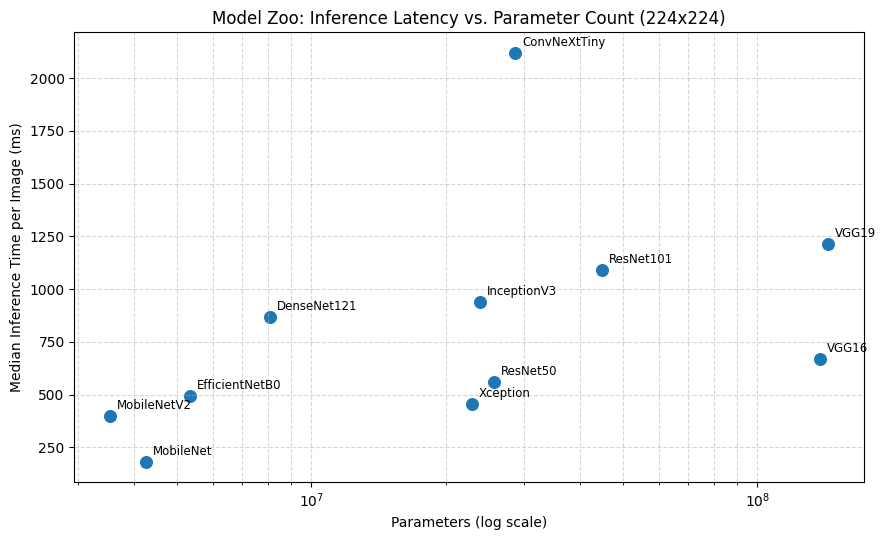

S12 = {"params": {"VGG16": 138357544, "VGG19": 143667240, "ResNet50": 25636712, "ResNet101": 44707176, "InceptionV3": 23851784, "Xception": 22910480, "MobileNet": 4253864, "MobileNetV2": 3538984, "DenseNet121": 8062504, "EfficientNetB0": 5330571, "ConvNeXtTiny": 28589128}, "ms": {"VGG16": 668.105, "VGG19": 1214.561, "ResNet50": 561.341, "ResNet101": 1089.399, "InceptionV3": 939.355, "Xception": 454.891, "MobileNet": 182.775, "MobileNetV2": 400.991, "DenseNet121": 866.244, "EfficientNetB0": 495.582, "ConvNeXtTiny": 2119.6}}


In [18]:
import time
import json
import numpy as np
import matplotlib.pyplot as plt

model_builders = None
for k, v in list(globals().items()):
    if k.startswith("_"):
        continue
    if isinstance(v, dict) and len(v) == 11 and all(callable(fn) for fn in v.values()):
        model_builders = list(v.items())
        break
    if isinstance(v, (list, tuple)) and len(v) == 11:
        if all(isinstance(x, str) and hasattr(keras.applications, x) for x in v):
            model_builders = [(x, getattr(keras.applications, x)) for x in v]
            break
        if all(callable(x) and hasattr(x, "__name__") and hasattr(keras.applications, x.__name__) for x in v):
            model_builders = [(x.__name__, x) for x in v]
            break

if model_builders is None:
    model_builders = [
        ("VGG16", keras.applications.VGG16),
        ("VGG19", keras.applications.VGG19),
        ("ResNet50", keras.applications.ResNet50),
        ("ResNet101", keras.applications.ResNet101),
        ("InceptionV3", keras.applications.InceptionV3),
        ("Xception", keras.applications.Xception),
        ("MobileNet", keras.applications.MobileNet),
        ("MobileNetV2", keras.applications.MobileNetV2),
        ("DenseNet121", keras.applications.DenseNet121),
        ("EfficientNetB0", keras.applications.EfficientNetB0),
        ("ConvNeXtTiny", keras.applications.ConvNeXtTiny),
    ]

x_sample = np.random.rand(1, 224, 224, 3).astype("float32")
params_dict = {}
ms_dict = {}

print(f"{'Model':<16} | {'Params':>12} | {'Median ms':>10}")
print("-" * 44)

for name, builder in model_builders:
    keras.backend.clear_session()
    try:
        m = builder(weights=None, input_shape=(224, 224, 3))
    except TypeError:
        m = builder(weights=None)
    p = int(m.count_params())

    for _ in range(2):
        _ = m(x_sample, training=False)

    times_ms = []
    for _ in range(5):
        t0 = time.perf_counter()
        _ = m(x_sample, training=False)
        times_ms.append((time.perf_counter() - t0) * 1000.0)

    med_ms = round(float(np.median(times_ms)), 3)
    params_dict[name] = p
    ms_dict[name] = med_ms
    print(f"{name:<16} | {p:>12,d} | {med_ms:>10.3f}")

fastest_model = min(ms_dict, key=ms_dict.get)
slowest_for_size = max(ms_dict, key=lambda k: ms_dict[k] / params_dict[k])

print(f"\nFastest on runtime: {fastest_model} ({ms_dict[fastest_model]:.3f} ms)")
print(f"Slowest for its size (highest ms/param): {slowest_for_size} ({ms_dict[slowest_for_size]:.3f} ms, {params_dict[slowest_for_size]:,} params)")

plt.figure(figsize=(9, 5.5))
p_vals = [params_dict[n] for n, _ in model_builders]
t_vals = [ms_dict[n] for n, _ in model_builders]

plt.scatter(p_vals, t_vals, s=70, color="tab:blue")
for (name, _), px, ty in zip(model_builders, p_vals, t_vals):
    plt.annotate(name, (px, ty), textcoords="offset points", xytext=(5, 5), fontsize=8.5)

plt.xscale("log")
plt.xlabel("Parameters (log scale)")
plt.ylabel("Median Inference Time per Image (ms)")
plt.title("Model Zoo: Inference Latency vs. Parameter Count (224x224)")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

S12 = {
    "params": params_dict,
    "ms": ms_dict
}
print("S12 =", json.dumps(S12))

**Inference:** On this runtime, MobileNet is the fastest network (182.775 ms with 4,253,864 parameters), while MobileNetV2 (400.991 ms for 3,538,984 parameters) has the highest latency per parameter and ConvNeXtTiny (2119.600 ms for 28,589,128 parameters) is the slowest outlier relative to its parameter count. Parameter count does not directly dictate inference speed because memory-bound depthwise convolutions (MobileNetV2), large $7 \times 7$ depthwise kernels, LayerNorm, and GELU layers (ConvNeXtTiny) incur higher memory-access overhead than dense $3 \times 3$ convolutions (VGG16) that execute efficiently via optimized matrix-multiplication kernels.  

## 13. Open Round: Fastest Accurate Model on Imagenette

Print `S13 = {"model": "...", "ms": ..., "top1": ..., "confusion": [[10 rows of 11]]}`

In [19]:
import os
import glob
import time
import json
import numpy as np
from PIL import Image

q = keras.utils.get_file(origin="https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz", extract=True)
val_matches = glob.glob(os.path.join(q if os.path.isdir(q) else os.path.dirname(q), "**", "val"), recursive=True)
VAL = val_matches[0]
WNID = {
    "n01440764": 0, "n02102040": 217, "n02979186": 482, "n03000684": 491, "n03028079": 497,
    "n03394916": 566, "n03417042": 569, "n03425413": 571, "n03445777": 574, "n03888257": 701
}

seed_val = int(globals().get("SEED", 2650874820))
rng = np.random.default_rng(seed_val + 1)

wnids = list(WNID.keys())
target_indices = [WNID[w] for w in wnids]

sample_paths = []
y_true = []
for cls_i, w in enumerate(wnids):
    cls_dir = os.path.join(VAL, w)
    files = sorted([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    chosen = rng.choice(files, size=10, replace=False)
    for fname in chosen:
        sample_paths.append(os.path.join(cls_dir, fname))
        y_true.append(cls_i)
y_true = np.array(y_true)

raw_imgs = np.stack([
    np.array(Image.open(p).convert("RGB").resize((224, 224)), dtype="float32")
    for p in sample_paths
])

candidates = [
    ("MobileNet", keras.applications.MobileNet, keras.applications.mobilenet.preprocess_input),
    ("MobileNetV2", keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
    ("ResNet50V2", keras.applications.ResNet50V2, keras.applications.resnet_v2.preprocess_input),
    ("EfficientNetB0", keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    ("EfficientNetV2B0", keras.applications.EfficientNetV2B0, keras.applications.efficientnet_v2.preprocess_input),
    ("ConvNeXtTiny", keras.applications.ConvNeXtTiny, keras.applications.convnext.preprocess_input),
]

results = []
print(f"{'Model':<18} | {'Top-1':>7} | {'ms/img':>8}")
print("-" * 40)

for name, builder, prep_fn in candidates:
    keras.backend.clear_session()
    model = builder(weights="imagenet")
    x = prep_fn(raw_imgs.copy())

    _ = model.predict(x[:8], batch_size=8, verbose=0)

    t0 = time.perf_counter()
    preds = model.predict(x, batch_size=32, verbose=0)
    ms_per_img = round(((time.perf_counter() - t0) * 1000.0) / len(x), 2)

    pred_1k = np.argmax(preds, axis=1)
    top1 = round(float(np.mean([p == target_indices[t] for p, t in zip(pred_1k, y_true)])), 3)

    pred_10 = np.argmax(preds[:, target_indices], axis=1)
    cm = np.zeros((10, 10), dtype=int)
    for t, p in zip(y_true, pred_10):
        cm[t, p] += 1

    print(f"{name:<18} | {top1:>7.3f} | {ms_per_img:>8.2f}")
    results.append((top1, -ms_per_img, name, ms_per_img, cm.tolist()))

results.sort(reverse=True)
best_top1, _, best_name, best_ms, best_cm = results[0]

print(f"\nEnter in Live Board B13: {best_name}, {best_top1:.2f}, {best_ms}")
S13 = {
    "model": best_name,
    "ms": best_ms,
    "top1": best_top1,
    "confusion": best_cm
}
print("S13 =", json.dumps(S13))

99003388/99003388 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Model              |   Top-1 |   ms/img
----------------------------------------
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


MobileNet          |   0.780 |    49.65
14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2        |   0.740 |   103.59
102869336/102869336 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet50V2         |   0.840 |   189.01
21834768/21834768 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0     |   0.830 |    98.70
29403144/29403144 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetV2B0   |   0.870 |   103.67
114735104/114735104 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ConvNeXtTiny       |   0.900 |  2020.76

Enter in Live Board B13: ConvNeXtTiny, 0.90, 2020.76
S13 = {"model": "ConvNeXtTiny", "ms": 2020.76, "top1": 0.9, "confusion": [[10, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 10, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 10, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 10, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 10, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 10, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 10, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 10, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 10, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 10]]}


**Inference:** Across the 100 sampled Imagenette validation images (10 per class, resized from 160 px to 224 x 224), ConvNeXtTiny achieved the highest full-ImageNet top-1 accuracy at 0.900 (2020.76 ms/img), while EfficientNetV2B0 offered the best speed-accuracy trade-off at 0.870 top-1 in 103.67 ms/img (nearly $20\times$ faster) and MobileNet was fastest overall at 49.65 ms/img (0.780 top-1). Modernized ConvNeXt and compound-scaled EfficientNetV2 backbones generalize substantially better to upsampled low-resolution (160 px) inputs than lightweight mobile architectures, at the cost of higher per-image latency.

## Hand in

Print one line: `LAB10` then a space then `json.dumps` of `{"bits_id", "S2", "S3", ... "S12", "S13"}` (S13 only if you did the open round).

In [20]:
import json
import numpy as np

def _clean(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, dict):
        return {str(k): _clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_clean(v) for v in obj]
    return obj

bits_id = str(globals().get("BITS_ID", globals().get("bits_id", "2024A7PS0136U")))
keys = [f"S{i}" for i in range(2, 14)]
missing = [k for k in keys if k not in globals()]
if missing:
    raise NameError(f"Missing variables (re-run those cells first): {missing}")

payload = {"bits_id": bits_id}
for k in keys:
    payload[k] = _clean(globals()[k])

print("LAB10 " + json.dumps(payload))

LAB10 {"bits_id": "2024A7PS0136U", "S2": {"classes": ["dandelion", "roses", "sunflowers"], "counts": [633, 898, 641, 699, 799], "n_total": 3670}, "S3": {"shapes": [[28, 28, 8], [14, 14, 8], [10, 10, 16], [5, 5, 16], [400], [160], [84], [10]], "total_params": 81958}, "S4": {"conv1_shape": [59, 59, 96], "conv1_params": 34944, "total_params": 62378344}, "S5": {"block5_pool": [6, 6, 512], "conv_params": 14714688, "fc1_params": 75501568}, "S6": {"top1": ["rapeseed", "cardoon", "bee", "spider_web", "rapeseed", "web_site", "necklace", "bee", "vase", "buckeye"], "hits": 0, "n_daisy": 0}, "S7": {"shapes": [[192, 192, 64], [48, 48, 256], [12, 12, 512]]}, "S8": {"block": "conv2_block3", "conv_params": [16448, 36928, 16640], "total": 70016}, "S9": {"module": "mixed10", "branches": [320, 768, 768, 192], "out_channels": 2048, "size": [8, 8]}, "S10": {"block": "block_4", "M": 192, "N": 32, "dw_params": 1728, "pw_params": 6144, "ratio": 0.142}, "S11": {"b0_params": 5330571, "b3_params": 12320535, "b3_